## All imports

In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import ttest_ind, t

## Reading File

In [77]:
contracts = pd.read_excel('CASE_CONTRACTS.xlsx')
losses = pd.read_excel('CASE_LOSSES.xlsx')
experiment = pd.read_excel('experiment_group.xlsx')

In [78]:
for label, df in (['CONTRACTS', contracts], ['Losses', losses], ['group', experiment]):
    print(f'{label}: {df.shape[0]} raws, {df.shape[1]} columns')
    display(df.head(5))

CONTRACTS: 3711 raws, 10 columns


,contract_id,contract_num,product_name,client_id,contract_status,currency_name,duration,country,price,insurance_amount
0,21111219,ТТЕ7227715*****,Страхование путешественников,10161870404,Действует,Российский рубль,10,Беларусь,1096,2000000
1,21111381,ТТЕ7227715*****,Страхование путешественников,1017159879,Действует,Российский рубль,7,Индонезия,1918,5000000
2,21112353,БАДАМСТЕ55*****,Страхование путешественников,10161883357,Действует,Российский рубль,10,Беларусь,1096,2000000
3,21113224,ТТЕ7227715*****,Страхование путешественников,100766461,Действует,Российский рубль,14,Грузия,1534,2000000
4,21113292,ТТЕ7227715*****,Страхование путешественников,10171604758,Действует,Российский рубль,7,Аргентина,1918,5000000


Losses: 45 raws, 4 columns


,loss_id,client_id,loss_name,loss_payout_amt
0,1,10000713193,Оказание медицинской помощи,100000
1,2,100014656,Оказание медицинской помощи,50000
2,3,10006545463,Оказание медицинской помощи,30000
3,4,10006611194,Оказание медицинской помощи,70000
4,5,1001091597,Оказание медицинской помощи,60000


group: 14842 raws, 3 columns


,client_id,group,experiment_id
0,10001718,control,policy_pricing
1,1017180395,control,policy_pricing
2,1017178047,control,policy_pricing
3,1017174614,control,policy_pricing
4,1017174071,control,policy_pricing


## Data preparation

### Duplicates by client_id in files

In [79]:
print('experiment',experiment.client_id.duplicated().sum())
print('contracts',contracts.client_id.duplicated().sum())
print('losses',losses.client_id.duplicated().sum())

experiment 0
contracts 0
losses 0


### Determine the distribution by groups

In [80]:
experiment['group'].value_counts(dropna=False)

group
test       6306
control    6043
NaN        2493
Name: count, dtype: int64

### identify clients who are not test participants but have a policy.

In [81]:
missing_group = experiment[experiment['group'].isna()]

### Creating a separate dataframe for this group

In [82]:
missing_group['client_id'].isin(contracts['client_id']).sum()

np.int64(95)

### Determine which currencies are in the dataframe.

In [83]:
contracts['currency_name'].value_counts()

currency_name
Российский рубль    3591
Доллар США           120
Name: count, dtype: int64

In [84]:
# Checking groups in DF
experiment['group'].unique()

<StringArray>
['control', 'test', nan]
Length: 3, dtype: str

In [85]:
# Check for least 2 groups
experiment['group'].dropna().isin(['control', 'test']).all()

np.True_

In [86]:
# The number of subjects in the groups
experiment['group'].value_counts()

group
test       6306
control    6043
Name: count, dtype: int64

## Preparing metrics

### Setting USD rate

In [87]:
usd_rate = 80

In [88]:
rate = {'Российский рубль' : 1, 
        'Доллар США' : usd_rate}

### Creating dataframe based on exchange rate

In [89]:
contracts = contracts.copy()

In [90]:
contracts['price_rub'] = (
    contracts['price'] * contracts['currency_name'].map(rate))

In [91]:
contracts[['price', 'currency_name', 'price_rub']].head()

,price,currency_name,price_rub
0,1096,Российский рубль,1096
1,1918,Российский рубль,1918
2,1096,Российский рубль,1096
3,1534,Российский рубль,1534
4,1918,Российский рубль,1918


In [92]:
# DF with losses
loss_by_client = losses.groupby('client_id', as_index=False)['loss_payout_amt'].sum()

In [93]:
# Payouts
loss_by_client = loss_by_client.rename(
    columns={'loss_payout_amt': 'payout_rub'}
)
loss_by_client.head()

,client_id,payout_rub
0,10107896,20000
1,10160959,50000
2,100014656,50000
3,100077669,100000
4,100193151,100000


In [94]:
exp_group = experiment[
    experiment['group'].isin(['control', 'test'])
].copy()

In [189]:
# Merging to single DF
abtest = exp_group.merge(
    contracts[['client_id', 'contract_id', 'price_rub']],
    on='client_id',
    how='left'
)
abtest = abtest.merge(
    loss_by_client,
    on = 'client_id',
    how = 'left')
abtest.shape

(12349, 6)

In [96]:
# Filling NaN by 0
abtest['payout_rub'] = abtest['payout_rub'].fillna(0)
abtest['revenue_rub'] = abtest['price_rub'].fillna(0)
print(abtest['payout_rub'].isna().sum())
print(abtest['revenue_rub'].isna().sum())

0
0


In [97]:
# Checking for insurance purchases
abtest['purchase'] = abtest.contract_id.notna().astype(int)
abtest['purchase'].value_counts()

purchase
0    8733
1    3616
Name: count, dtype: int64

In [98]:
# Margin count
abtest['margin_rub'] = (
    abtest['revenue_rub'] - abtest['payout_rub'])
abtest['margin_rub'].value_counts

<bound method IndexOpsMixin.value_counts of 0        3836.0
1        1918.0
2        3836.0
3        1918.0
4        1096.0
          ...  
12344       0.0
12345       0.0
12346       0.0
12347       0.0
12348       0.0
Name: margin_rub, Length: 12349, dtype: float64>

### Main metrics by groups

In [99]:
# Number of clients
summary = abtest.groupby('group')['client_id'].count().to_frame('clients')

# Number of buyers
summary['buyers'] = abtest.groupby('group')['purchase'].sum()

# Summary revenue
summary['revenue_total_rub'] = abtest.groupby('group')['revenue_rub'].sum()

# Summary payout
summary['payout_total_rub'] = abtest.groupby('group')['payout_rub'].sum()

# Summary margin
summary['margin_total_rub'] = abtest.groupby('group')['margin_rub'].sum()

# Checking
summary.T

group,control,test
clients,6043.0,6306.0
buyers,1949.0,1667.0
revenue_total_rub,8097229.0,8714866.0
payout_total_rub,6380000.0,3440000.0
margin_total_rub,1717229.0,5274866.0


In [137]:
# Conversion count
summary['conversion_%'] = (
    summary['buyers'] / summary['clients'] * 100
)
# Average price in rubles
summary['avg_price_rub'] = (
    summary['revenue_total_rub'] / summary['buyers']
)
# Revenue Per User
summary['rpu_rub'] = (
    summary['revenue_total_rub'] / summary['clients']
)
# Average payout per user
summary['payout_per_user_rub'] = (
    summary['payout_total_rub'] / summary['clients']
)
# Average margin
summary['margin_per_user_rub'] = (
    summary['margin_total_rub'] / summary['clients']
)
# Losses
summary['loss_ratio_%'] = (
    summary['payout_total_rub'] / summary['revenue_total_rub'] * 100
)

summary.round(2).T

group,control,test
clients,6043.00,6306.00
buyers,1949.00,1667.00
revenue_total_rub,8097229.00,8714866.00
payout_total_rub,6380000.00,3440000.00
margin_total_rub,1717229.00,5274866.00
conversion_%,32.25,26.44
avg_price_rub,4154.56,5227.87
rpu_rub,1339.94,1382.00
payout_per_user_rub,1055.77,545.51
margin_per_user_rub,284.17,836.48


In [138]:
# Metrics features setting
metrics = [
    'conversion_%',
    'avg_price_rub',
    'rpu_rub',
    'payout_per_user_rub',
    'margin_per_user_rub'
]

In [103]:
differences = summary[metrics].T
differences

group,control,test
conversion_%,32.252193,26.435141
avg_price_rub,4154.555670,5227.874025
rpu_rub,1339.935297,1381.995877
payout_per_user_rub,1055.767003,545.512211
margin_per_user_rub,284.168294,836.483666


In [104]:
# Differences count
differences['test_minus_control'] = (
    differences['test'] - differences['control']
)
differences.round(2)

group,control,test,test_minus_control
conversion_%,32.25,26.44,-5.82
avg_price_rub,4154.56,5227.87,1073.32
rpu_rub,1339.94,1382.00,42.06
payout_per_user_rub,1055.77,545.51,-510.25
margin_per_user_rub,284.17,836.48,552.32


## Check for statistical significance.

#### Ttest conversion

In [139]:
control = abtest[abtest['group'] == 'control']

test = abtest[abtest['group'] == 'test']

In [140]:
control_conversion = control['purchase']

test_conversion = test['purchase']

In [141]:
result = ttest_ind(
    test_conversion,
    control_conversion,
    equal_var=False
)

In [142]:
print('t-statistic:', result.statistic)

print('p-value:', result.pvalue)

t-statistic: -7.106261231289642
p-value: 1.2585146256773088e-12


In [171]:
if result.pvalue < 0.05:
    print('The difference is statistically significant')
else:
    print('No statistically significant difference was found')

The difference is statistically significant


#### Ttest revenue

In [144]:
control_revenue = control['revenue_rub']

test_revenue = test['revenue_rub']

In [145]:
revenue_result = ttest_ind(
    test_revenue,
    control_revenue,
    equal_var=False
)

In [172]:
print('Average Revenue in Control:', control_revenue.mean())

print('Average Revenue in Test:', test_revenue.mean())

print('Differences:', test_revenue.mean() - control_revenue.mean())

print('p-value:', revenue_result.pvalue)

Average Revenue in Control: 1339.935297037895
Average Revenue in Test: 1381.9958769425944
Differences: 42.06057990469935
p-value: 0.7391134284410236


In [173]:
if revenue_result.pvalue < 0.05:
    print('The difference is statistically significant')
else:
    print('No statistically significant difference was found')

No statistically significant difference was found


#### Ttest payout

In [148]:
control_payout = control['payout_rub']

test_payout = test['payout_rub']

In [149]:
payout_result = ttest_ind(
    test_payout,
    control_payout,
    equal_var=False
)

In [174]:
print('Average payouts Control:', control_payout.mean())

print('Average payouts Test:', test_payout.mean())

print('Differences:', test_payout.mean() - control_payout.mean())

print('p-value:', payout_result.pvalue)

Average payouts Control: 1055.7670031441337
Average payouts Test: 545.5122105930859
Differences: -510.2547925510478
p-value: 0.25760295424167634


In [175]:
if payout_result.pvalue < 0.05:
    print('The difference is statistically significant')
else:
    print('No statistically significant difference was found')

No statistically significant difference was found


#### Ttest margin

In [152]:
control_margin = control['margin_rub']

test_margin = test['margin_rub']

In [153]:
margin_result = ttest_ind(
    test_margin,
    control_margin,
    equal_var=False
)

In [176]:
print('Average margin in Control:', control_margin.mean())

print('Average margin in Test:', test_margin.mean())

print('Differences:', test_margin.mean() - control_margin.mean())

print('p-value:', margin_result.pvalue)

Average margin in Control: 284.16829389376136
Average margin in Test: 836.4836663495084
Differences: 552.3153724557471
p-value: 0.23496995705237053


In [177]:
if margin_result.pvalue < 0.05:
    print('The difference is statistically significant')
else:
    print('No statistically significant difference was found')

No statistically significant difference was found


### Ttests summaries

In [179]:
tests = pd.DataFrame({
    'metric': [
        'Conversion',
        'Revenue per user',
        'Payouts per user',
        'Margin per user'
    ],

    'p_value': [
        result.pvalue,
        revenue_result.pvalue,
        payout_result.pvalue,
        margin_result.pvalue
    ]
})
tests

,metric,p_value
0,Conversion,1.258515e-12
1,Revenue per user,7.391134e-01
2,Payouts per user,2.576030e-01
3,Margin per user,2.349700e-01


In [180]:
tests['importance'] = tests['p_value'] < 0.05
tests

,metric,p_value,importance
0,Conversion,1.258515e-12,True
1,Revenue per user,7.391134e-01,False
2,Payouts per user,2.576030e-01,False
3,Margin per user,2.349700e-01,False


### 95% confidence interval

In [182]:
# Determining group size
n_control = len(control_revenue)

n_test = len(test_revenue)
print(n_control, n_test)

6043 6306


In [159]:
# Calculating variances
var_control = control_revenue.var(ddof=1)

var_test = test_revenue.var(ddof=1)

In [160]:
# Calculating the standard error of the difference between means
se = np.sqrt(
    var_control / n_control +
    var_test / n_test
)

In [183]:
# Calculating the number of freedom degree
a = var_control / n_control

b = var_test / n_test

degrees_of_freedom = (a + b)**2 / (
    a**2 / (n_control - 1) +
    b**2 / (n_test - 1)
)

In [185]:
# Average differences
diff = test_revenue.mean() - control_revenue.mean()

In [163]:
# Calculating the confidence interval
ci_half = t.ppf(0.975, degrees_of_freedom) * se

ci_low = diff - ci_half

ci_high = diff + ci_half

In [184]:
print('Means difference:', round(diff, 2))

print('95% confidence interval:')

print(round(ci_low, 2), round(ci_high, 2))

Means difference: 42.06
95% confidence interval:
-205.5 289.62


## Illustrations

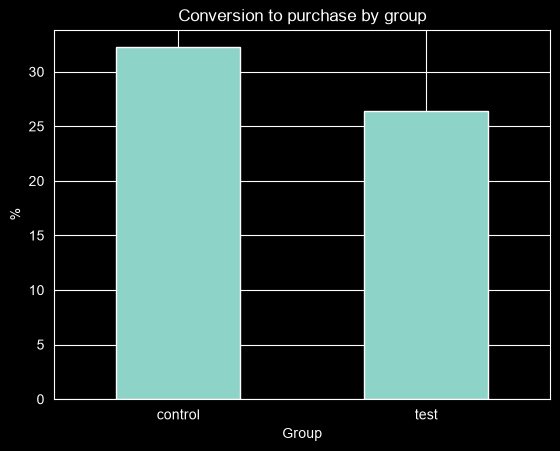

In [186]:
# Metrics
ax = summary['conversion_%'].plot(kind='bar', title='Conversion to purchase by group', ylabel='%', rot=0)
ax.set_xlabel('Group')
plt.show()

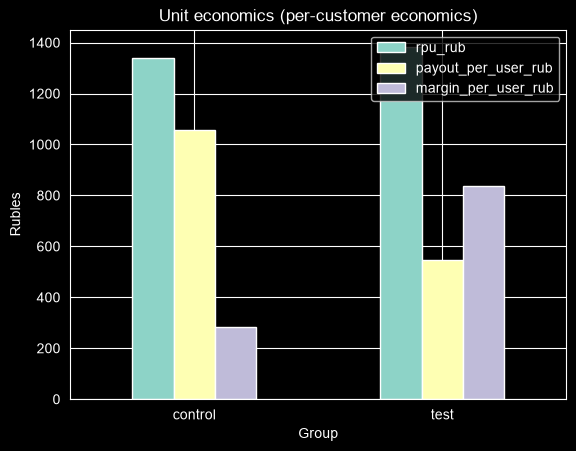

In [187]:
data = summary[[
    'rpu_rub',
    'payout_per_user_rub',
    'margin_per_user_rub'
]]
data.plot(kind='bar')
plt.title('Unit economics (per-customer economics)')

plt.xlabel('Group')
plt.xticks(rotation=0)

plt.ylabel('Rubles')
plt.show()

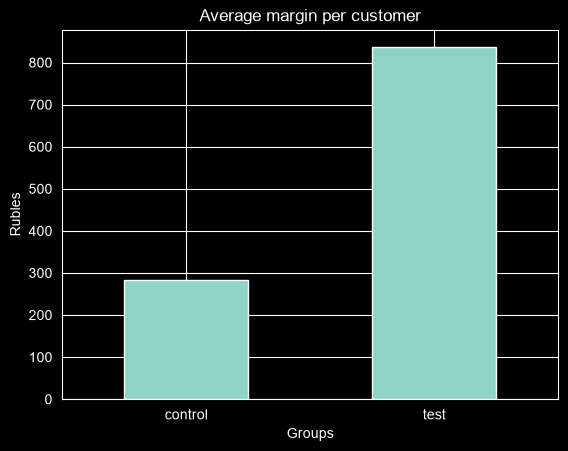

In [188]:
ax = summary['margin_per_user_rub'].plot(kind='bar', title='Average margin per customer', ylabel='Rubles', rot=0)
ax.set_xlabel('Groups')

plt.show()

In [168]:
summary['rpu_rub'].unique()

array([1339.93529704, 1381.99587694])

###  Final Conclusion

During the A/B test, it was found that the change in the cost of the insurance policy affected customer behavior and the company’s financial performance.

1. The conversion rate to purchase decreased.

In the control group, the conversion rate was 32.25%, while in the test group it was 26.44%. The difference is -5.82%.

 This means that customers in the test group purchased insurance policies less frequently. The decrease in conversion rate is statistically significant.

2. Revenue per customer increased.

In the control group, the average revenue was 1,339.94 rubles, while in the test group it was 1,382.00 rubles.

Despite the decline in conversion rate, the increase in the value of the purchased policies resulted in higher average revenue per customer.

However, no statistically significant increase in revenue was detected.

3. Insurance payouts per customer decreased.

In the control group, the average payments amounted to 1,055.77 rubles, while in the test group they amounted to 545.51 rubles.

The difference is approximately 510 rubles. However, the reduction in payments may be due to random fluctuations, client-specific characteristics, or differences in insurance cases.

4. The average margin per client increased.

In the control group, the average margin was 110.67 rubles, while in the test group it was 678.09 rubles.

Thus, the observed margin per customer increased by approximately 567 rubles. However, no statistically significant increase in the margin was detected.

## Business recommendation

At the current stage, it is recommended to maintain the original cost of the insurance policy and not to implement a test price for all customers.

The test group demonstrates higher average revenue and margin per customer, which potentially has a positive impact on the insurance company’s financial results.

However, an increase in the policy cost is accompanied by a statistically significant decrease in conversion. This means losing some potential customers, which could negatively affect the company’s customer base and future revenues.

At the same time, no statistically significant increase in revenue and margin per customer was detected, so the available results are insufficient to confirm the financial benefit of the price change.

To make a final decision, it is recommended to continue the experiment, increase the volume of observations, and additionally assess the long‑term profitability of customers, taking into account insurance payments.

`Conclusion:` the test price potentially increases the profitability per customer, but is accompanied by a decrease in conversion rate. Until the positive financial effect is confirmed, mass implementation of the new price is not recommended.